# How the cell-cycle model works

The [cell-cycle tutorial](cell_cycle.ipynb) shows how to call {func}`~mantispy.tl.fit_cell_cycle` and
{func}`~mantispy.tl.project_cell_cycle`. The notebook here explains the model one step and one figure at a time. Most
figures use small simulated populations, where the true cycle position of every cell is known, so each step can be
checked against the truth. Real cells from the optical pooled screen appear only where they show something a
simulation cannot.

A few cells call private helpers of {mod}`mantispy.tl` to draw the model's internals. They are marked as such and are
not part of the public interface.

In [1]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import mantispy as mt

plt.rcParams["figure.dpi"] = 110


def simulate(n_cells=6000, background=0.0, seed=0):
    """A growing population: G1 until 0.45 of the cycle, S until 0.75, then G2M, with DNA doubling through S."""
    rng = np.random.default_rng(seed)
    age = -np.log2(1 - rng.random(n_cells) / 2)  # the age distribution of a growing population
    progress = np.clip((age - 0.45) / 0.3, 0, 1)  # how far replication has gone
    amount = 1 + progress  # DNA amount, 1 in G1 and 2 in G2M
    integrated = 1000 * amount * 2 ** rng.normal(0, 0.04, n_cells) + background
    tubulin = 1 + 2 * np.clip(age - 0.45, 0, None) + rng.normal(0, 0.03, n_cells)  # rises from S onwards
    size = rng.normal(0, 0.25, n_cells)  # how large a cell is, unrelated to its age
    area = 1000 * 2 ** (0.8 * age + size)
    solidity = np.clip(rng.normal(0.975, 0.004, n_cells), 0, 1)
    noise = rng.normal(0, 1, (n_cells, 4))
    names = [
        "Nuclei_Intensity_IntegratedIntensity_DNA",
        "Cells_Intensity_MeanIntensity_Tubulin",
        "Nuclei_AreaShape_Area",
        "Nuclei_AreaShape_Solidity",
    ] + [f"Cells_Texture_Noise_{i}" for i in range(4)]
    obs = pd.DataFrame(
        {
            "Metadata_Plate": "P1",
            "Metadata_Well": [f"W{i % 4}" for i in range(n_cells)],
            "Metadata_Control_Type": "negcon",
            "age": age,
            "size": size,
            "true_phase": np.where(age < 0.45, "G1", np.where(age < 0.75, "S", "G2M")),
        },
        index=[str(i) for i in range(n_cells)],
    )
    X = np.column_stack([integrated, tubulin, area, solidity, noise])
    var = pd.DataFrame({"channel": ["DNA", "Tubulin", "", "", "", "", "", ""]}, index=names)
    return ad.AnnData(X=X, obs=obs, var=var)

## The input: DNA content

The model reads one number per cell, the integrated intensity of its DNA stain. {func}`~mantispy.tl.dna_content` takes its
log2 and subtracts the log2 of the G1 peak, so a G1 cell sits near 0 and a cell with twice the DNA near 1. The unit is
a doubling.

A doubling of DNA gives 1 only if the intensity is proportional to the DNA. A constant background added to every
nucleus breaks that. With a G1 intensity a and a background b, the 4N peak sits at the log2 of (2a + b) / (a + b),
which is below 1. The two simulations
below differ only in a background of a fifth of the G1 intensity.

no background: 4N peak near 0.99


background of 200: 4N peak near 0.87


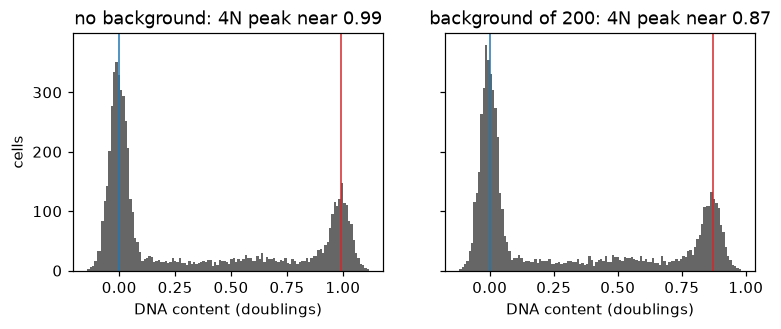

expected 4N position with background: 0.87


In [2]:
clean, shifted = simulate(), simulate(background=200.0)
figure, axes = plt.subplots(1, 2, figsize=(8, 2.8), sharey=True)
for axis, cells, title in zip(axes, (clean, shifted), ("no background", "background of 200"), strict=True):
    mt.tl.dna_content(cells, dna_feature="Nuclei_Intensity_IntegratedIntensity_DNA", reference="negcon")
    content = cells.obs["Metadata_DNAContent"]
    peak = content[content > 0.6].round(2).mode().iloc[0]
    axis.hist(content, bins=120, color="0.4")
    axis.axvline(0, color="tab:blue", lw=1)
    axis.axvline(peak, color="tab:red", lw=1)
    axis.set(title=f"{title}: 4N peak near {peak:.2f}", xlabel="DNA content (doublings)")
    print(f"{title}: 4N peak near {peak:.2f}")
axes[0].set_ylabel("cells")
plt.show()
print("expected 4N position with background:", round(np.log2(2200 / 1200), 2))

Without background the 4N peak sits near 0.99. With a background of a fifth of the G1 intensity it sits near
0.87, as the formula gives. The model reads the 4N peak from the data, so it follows such a shift.

## The template

The model describes the DNA content a cell should have at each point of its cycle. Through G1 it is flat at the 2N
peak. Through S, DNA is copied at a steady rate, so the amount of DNA, not its logarithm, rises along a straight line.
Through G2 and mitosis it is flat at the 4N peak, and at division it drops back to 2N, where the next cycle starts.
The model takes both peaks from the data rather than assuming 0 and 1.

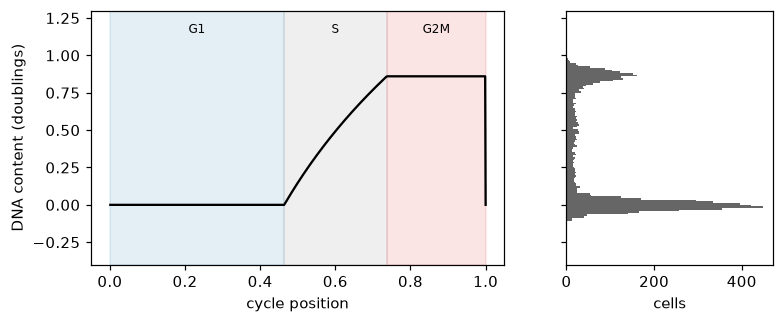

2N peak          0.000
4N peak          0.860
2N peak width    0.039
dtype: float64

In [3]:
# Private helpers, used here only to draw the model's internals.
from mantispy.tl._cell_cycle import _GRID, _LOG_PRIOR, _age, _template

cells = shifted
mt.tl.fit_cell_cycle(cells, reference="negcon", qc_features=("Nuclei_AreaShape_Area", "Nuclei_AreaShape_Solidity"))
model = cells.uns["mantispy"]["cell_cycle"]

expected, edges = _template(model)
figure, (left, right) = plt.subplots(1, 2, figsize=(8, 3), sharey=True, gridspec_kw={"width_ratios": [2, 1]})
for (start, end), name, color in zip(
    zip(edges[:-1], edges[1:], strict=True), ("G1", "S", "G2M"), ("tab:blue", "tab:grey", "tab:red"), strict=True
):
    left.axvspan(start, end, color=color, alpha=0.12)
    left.text((start + end) / 2, 1.15, name, ha="center", fontsize=8)
left.plot(np.r_[_GRID, 1.0], np.r_[expected, expected[0]], color="black")
left.set(xlabel="cycle position", ylabel="DNA content (doublings)", ylim=(-0.4, 1.3))
right.hist(cells.obs["Metadata_DNAContent"], bins=100, orientation="horizontal", color="0.4")
right.set(xlabel="cells")
plt.show()
pd.Series({"2N peak": model["peaks"][0], "4N peak": model["peaks"][1], "2N peak width": model["sd"]}).round(3)

In the simulation with background, the 2N peak sits at 0.000 and the 4N peak at 0.860, and the 2N peak width is
0.039 doublings, close to the 0.04 the simulation added. Through S the template curves, because a straight rise in
the amount of DNA is a curve in its logarithm. The histogram beside it shows the cells piled on the two flat parts.

## Ergodic rate analysis: from shares of cells to time

The fit gives the share of control cells in G1, S and G2M. Turning shares into time needs one fact about a growing
population {cite:p}`Kafri_2013`. Every division turns one old cell into two young ones, so in steady state young
cells outnumber old ones, and the density of cells of age t, as a share of the cycle, is 2 ln 2 times 2 to the power
-t. The share of cells younger than t is then F = 2(1 - 2^-t), so a cumulative share F corresponds to the age
t = -log2(1 - F/2). Reading the shares directly as time would make G1 look longer than it is.

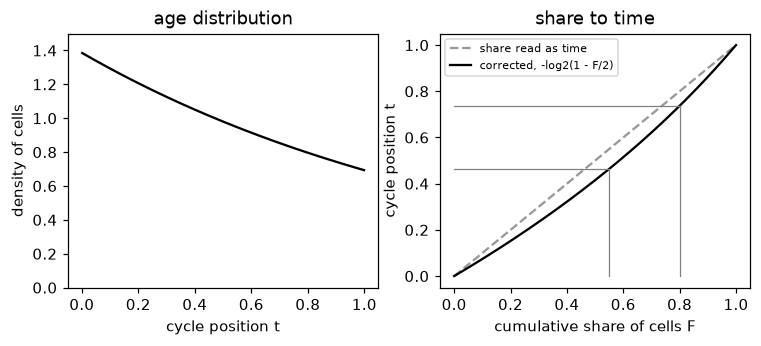

,fitted share of cells,true share of cells,share of the cycle,true share of the cycle
G1,0.55,0.536,0.464,0.45
S,0.25,0.272,0.273,0.30
G2M,0.20,0.192,0.263,0.25


In [4]:
share = np.linspace(0, 1, 201)
figure, (left, right) = plt.subplots(1, 2, figsize=(8, 3))
left.plot(_GRID, np.exp(_LOG_PRIOR), color="black")
left.set(xlabel="cycle position t", ylabel="density of cells", title="age distribution", ylim=(0, 1.5))
right.plot(share, share, color="0.6", ls="--", label="share read as time")
right.plot(share, _age(share), color="black", label="corrected, -log2(1 - F/2)")
cumulative = np.cumsum(model["fractions"])[:2]
for value in cumulative:
    right.plot([value, value], [0, _age(value)], color="tab:grey", lw=0.8)
    right.plot([0, value], [_age(value), _age(value)], color="tab:grey", lw=0.8)
right.set(xlabel="cumulative share of cells F", ylabel="cycle position t", title="share to time")
right.legend(fontsize=7)
plt.show()
truth = cells.obs["true_phase"].value_counts(normalize=True)
pd.DataFrame(
    {
        "fitted share of cells": model["fractions"],
        "true share of cells": [truth["G1"], truth["S"], truth["G2M"]],
        "share of the cycle": np.diff(np.r_[0, _age(cumulative), 1]),
        "true share of the cycle": [0.45, 0.30, 0.25],
    },
    index=["G1", "S", "G2M"],
).round(3)

The fitted shares of cells, 0.55, 0.25 and 0.20, are close to the true shares of 0.536, 0.272 and 0.192. After
the correction, the shares of the cycle come out as 0.464, 0.273 and 0.263, against the 0.45, 0.30 and 0.25 the
simulation used. Read directly as time, the shares of cells would have given G1 55% of the cycle instead of about
45%.

## The posterior for one cell

{func}`~mantispy.tl.project_cell_cycle` asks, for each cell, how probable each cycle position is given its DNA
content. The posterior combines a likelihood and a prior. The likelihood says how well the cell's DNA content fits the template at each position,
with the 2N peak width as the measurement noise. The prior is the age distribution above. Their product, normalized,
is the posterior. The cells below sit in G1, in the middle of S and in G2M.

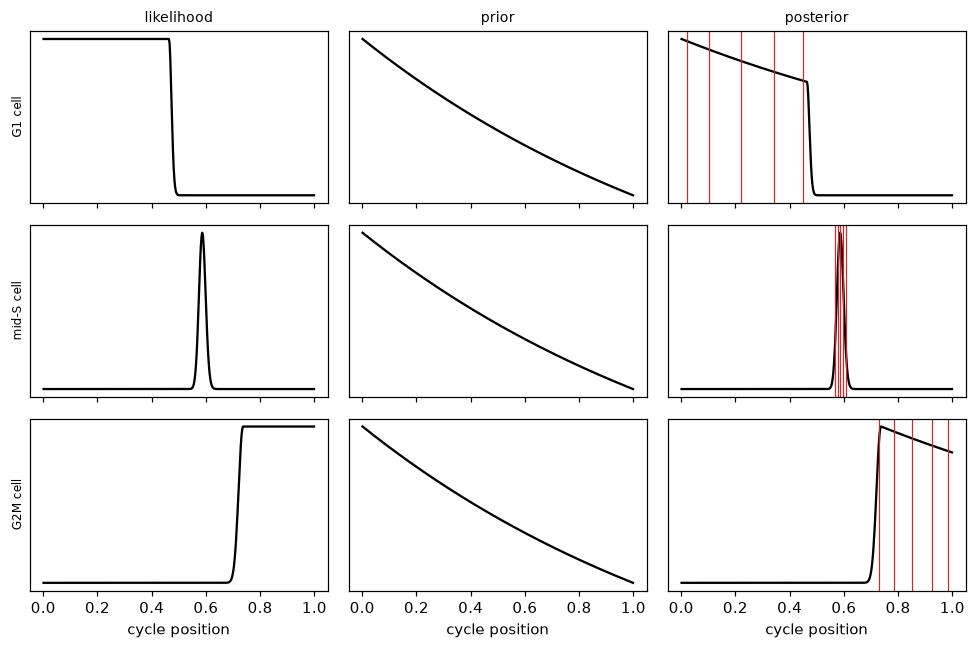

,G1,S,G2M,off-cycle,5%,25%,50%,75%,95%
G1 cell,0.98,0.02,0.00,0.0,0.02,0.10,0.22,0.34,0.45
mid-S cell,0.00,1.00,0.00,0.0,0.57,0.58,0.59,0.60,0.61
G2M cell,0.00,0.08,0.92,0.0,0.73,0.78,0.85,0.92,0.98


In [5]:
examples = pd.Series({"G1 cell": 0.0, "mid-S cell": 0.45, "G2M cell": model["peaks"][1]})
dna_only = {name: value for name, value in model.items() if name != "qc"}  # the probes carry no shape features
probe = ad.AnnData(obs=pd.DataFrame({"Metadata_DNAContent": examples.to_numpy()}, index=list(examples.index)))
mt.tl.project_cell_cycle(probe, model=dna_only, by=None)

figure, axes = plt.subplots(3, 3, figsize=(9, 6), sharex=True)
for row, (name, content) in enumerate(examples.items()):
    likelihood = np.exp(-0.5 * ((content - expected) / model["sd"]) ** 2)
    prior = np.exp(_LOG_PRIOR)
    posterior = likelihood * prior / (likelihood * prior).sum()
    for column, (curve, title) in enumerate(((likelihood, "likelihood"), (prior, "prior"), (posterior, "posterior"))):
        axes[row, column].plot(_GRID, curve, color="black")
        axes[row, column].set_yticks([])
        if row == 0:
            axes[row, column].set_title(title, fontsize=9)
    for q in probe.obsm["cell_cycle_quantiles"].loc[name]:
        axes[row, 2].axvline(q, color="tab:red", lw=0.8)
    axes[row, 0].set_ylabel(name, fontsize=8)
for axis in axes[-1]:
    axis.set_xlabel("cycle position")
plt.tight_layout()
plt.show()
pd.concat([probe.obsm["cell_cycle_probabilities"], probe.obsm["cell_cycle_quantiles"]], axis=1).round(2)

For the G1 cell, the likelihood is flat across all of G1, since every G1 position predicts the same DNA, so the
posterior is the prior cut off at the end of G1. Its 5% to 95% quantiles span 0.02 to 0.45. The mid-S cell's DNA
fits only a narrow stretch of S, and its quantiles span 0.57 to 0.61. The G2M cell spreads over G2M, from 0.73 to
0.98. The phase probabilities follow, at 0.98 for G1, 1.00 for S and 0.92 for G2M, with the rest on the neighboring
phase.

Summing the posterior over each phase gives the phase probabilities. Drawn against DNA content, they show where one
phase gives way to the next, and where a cell becomes more likely off the cycle than on it.

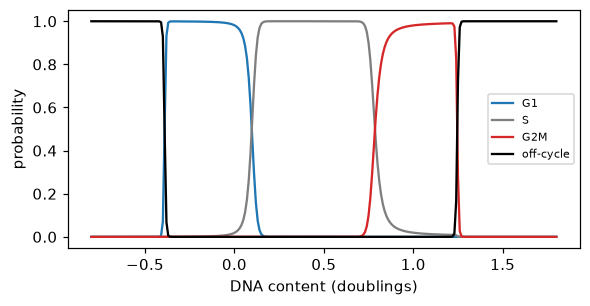

off the cycle below -0.4 and above 1.25


In [6]:
grid = np.linspace(-0.8, 1.8, 261)
probe = ad.AnnData(obs=pd.DataFrame({"Metadata_DNAContent": grid}, index=[str(i) for i in range(grid.size)]))
mt.tl.project_cell_cycle(probe, model=dna_only, by=None)
probabilities = probe.obsm["cell_cycle_probabilities"]
figure, axis = plt.subplots(figsize=(6, 2.8))
for phase, color in zip(probabilities.columns, ("tab:blue", "tab:grey", "tab:red", "black"), strict=True):
    axis.plot(grid, probabilities[phase], color=color, label=phase)
axis.set(xlabel="DNA content (doublings)", ylabel="probability")
axis.legend(fontsize=7)
plt.show()
off = probabilities["off-cycle"] > 0.5
print(
    "off the cycle below", round(grid[(grid < 0) & off].max(), 2), "and above", round(grid[(grid > 1) & off].min(), 2)
)

G1 gives way to S, and S to G2M, where the template leaves each peak. The change is as sharp as the 2N peak is
narrow. Below -0.4 doublings and above 1.25, the flat background wins and a cell is called off the cycle.

## The check before the fit

A model of the cycle only makes sense for a reference that cycles. Before fitting, the DNA content of the reference
must show a 2N peak, a separate 4N peak, a valley between them that S cells fill, and a share of cells in S. Three
populations that do not cycle fail it. They are a narrow line of DNA content just above 2N, a single 2N blob, and two clusters
at 2N and 4N with nothing between them.

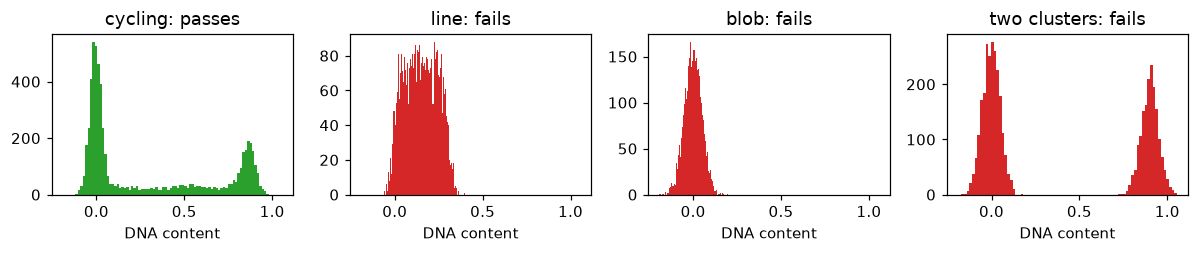

,4N peak at least a twentieth of the 2N peak,valley at most nine tenths of the 4N peak,S density at least a tenth of the 4N peak,at least 3% of cells in S,passes
cycling,True,True,True,True,True
line,False,False,False,False,False
blob,False,False,False,False,False
two clusters,True,True,False,False,False


In [7]:
from mantispy.tl._cell_cycle import _gate  # private helper, used here only to show the measures

rng = np.random.default_rng(1)
populations = {
    "cycling": cells.obs["Metadata_DNAContent"].to_numpy(),
    "line": rng.uniform(0, 0.3, 4000) + rng.normal(0, 0.03, 4000),
    "blob": rng.normal(0, 0.05, 4000),
    "two clusters": (rng.random(4000) < 0.4) * 0.9 + rng.normal(0, 0.05, 4000),
}
figure, axes = plt.subplots(1, 4, figsize=(11, 2.4), sharex=True)
report = {}
for axis, (name, content) in zip(axes, populations.items(), strict=True):
    report[name] = _gate(content)
    axis.hist(content, bins=80, color="tab:green" if report[name]["passed"] else "tab:red")
    axis.set(title=f"{name}: {'passes' if report[name]['passed'] else 'fails'}", xlabel="DNA content")
plt.tight_layout()
plt.show()
pd.DataFrame(
    {
        "4N peak at least a twentieth of the 2N peak": [r["peak_ratio"] >= 0.05 for r in report.values()],
        "valley at most nine tenths of the 4N peak": [r["valley_ratio"] <= 0.9 for r in report.values()],
        "S density at least a tenth of the 4N peak": [r["s_floor"] >= 0.1 for r in report.values()],
        "at least 3% of cells in S": [r["s_share"] >= 0.03 for r in report.values()],
        "passes": [r["passed"] for r in report.values()],
    },
    index=list(report),
)

The cycling population passes every criterion. The line and the blob fail every criterion, since neither has a
4N peak or cells in S. The two clusters have both peaks and a deep valley between them, but nothing fills S, so they
fail on the density across S and on the share of cells in S.

## Off the cycle, and nuclei that are not single cells

The model holds a flat background for cells that fit no part of the cycle, and its weight is fitted with the rest.
DNA content alone cannot see two other problems. Two touching G1 nuclei segmented as one hold 4N and look like a G2M
cell, and a fragment of a dying cell holds less than 2N. With ``qc_features``, the fit learns from the controls how
small and how irregular a nucleus may be, and flags nuclei beyond that. Below, the simulation gains 150 merged pairs
of G1 nuclei and 150 fragments.

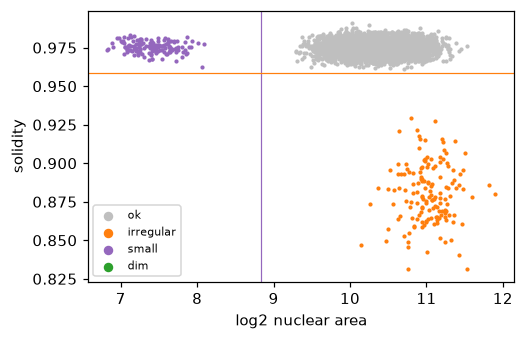

cell_cycle_phase G1  S G2M           off-cycle      
cell_cycle_qc    ok ok  ok irregular irregular small
true_phase                                          
merged pair       0  0   0       149         1     0
fragment          0  0   0         0         0   150

In [8]:
from mantispy.tl._cell_cycle import QC_FLAGS

rng = np.random.default_rng(2)
base = simulate(seed=3)
g1 = np.flatnonzero(base.obs["true_phase"] == "G1")[:300]
merged, fragments = base[g1[:150]].copy(), base[g1[150:]].copy()
merged.X[:, 0] *= 2
merged.X[:, 2] *= 1.8
merged.X[:, 3] = rng.normal(0.88, 0.02, 150)
fragments.X[:, 0] *= 0.35
fragments.X[:, 2] *= 0.15
merged.obs["true_phase"], fragments.obs["true_phase"] = "merged pair", "fragment"
merged.obs_names = [f"m{i}" for i in range(150)]
fragments.obs_names = [f"f{i}" for i in range(150)]
mixed = ad.concat([base, merged, fragments], merge="same")
mt.tl.dna_content(mixed, dna_feature="Nuclei_Intensity_IntegratedIntensity_DNA", reference="negcon")
mt.tl.fit_cell_cycle(mixed, reference="negcon", qc_features=("Nuclei_AreaShape_Area", "Nuclei_AreaShape_Solidity"))
mt.tl.project_cell_cycle(mixed)

cutoffs = mixed.uns["mantispy"]["cell_cycle"]["qc"]["cutoffs"]
figure, axis = plt.subplots(figsize=(5, 3.2))
for flag, color in zip(QC_FLAGS, ("0.75", "tab:orange", "tab:purple", "tab:green"), strict=True):
    rows = (mixed.obs["cell_cycle_qc"] == flag).to_numpy()
    axis.scatter(np.log2(mixed.X[rows, 2]), mixed.X[rows, 3], s=3, color=color, label=flag, rasterized=True)
axis.axvline(cutoffs[0], color="tab:purple", lw=0.8)
axis.axhline(cutoffs[1], color="tab:orange", lw=0.8)
axis.set(xlabel="log2 nuclear area", ylabel="solidity")
axis.legend(fontsize=7, markerscale=3)
plt.show()
pd.crosstab(mixed.obs["true_phase"], [mixed.obs["cell_cycle_phase"], mixed.obs["cell_cycle_qc"]]).loc[
    ["merged pair", "fragment"]
]

DNA content alone calls 149 of the 150 merged pairs G2M, since they hold 4N, and the shape check flags all 150
as irregular. The 150 fragments sit below 2N, so the model already calls them off the cycle, and the shape check adds
the reason, that they are small.

## The experimental G2M order, step by step

DNA content is flat through G2M, so the model above cannot order cells within it. The option ``refine_g2m=True``
tries to order them with the other features, without labels. It runs in four steps.

### Step 1: an S-phase axis from the other features

S cells carry their own progress label, their DNA content. On the controls, every feature not measured on the DNA
stain is scaled robustly, reduced to up to 30 principal components, and a ridge regression of DNA content on those
components is fitted on the S cells only. The fitted direction is the S axis. Each feature also gets a weight, the
size of its rank correlation with DNA content in S, which the later graph uses. In the simulation, tubulin rises
with progress from S onwards, area rises a little with age but varies far more from cell to cell, and four features
are noise.

In [9]:
# Private helpers, used here only to show the steps the package runs inside project_cell_cycle.
from mantispy.tl._cell_cycle import _g2m_order, _g2m_space, _rank01

sim = simulate(seed=4)
mt.tl.dna_content(sim, dna_feature="Nuclei_Intensity_IntegratedIntensity_DNA", reference="negcon")
mt.tl.fit_cell_cycle(sim, reference="negcon", refine_g2m=True)
mt.tl.project_cell_cycle(sim, by=None)
g2m_model = sim.uns["mantispy"]["cell_cycle"]["g2m"]

pd.Series(g2m_model["weights"], index=g2m_model["features"]).rename("weight in the graph space").round(3)

project_cell_cycle: the G2M order is experimental and cannot be validated without a marker of G2 and mitosis; check it against one before reading it biologically


Cells_Intensity_MeanIntensity_Tubulin    0.966
Nuclei_AreaShape_Area                    0.234
Nuclei_AreaShape_Solidity                0.010
Cells_Texture_Noise_0                    0.033
Cells_Texture_Noise_1                    0.013
Cells_Texture_Noise_2                    0.010
Cells_Texture_Noise_3                    0.004
Name: weight in the graph space, dtype: float64

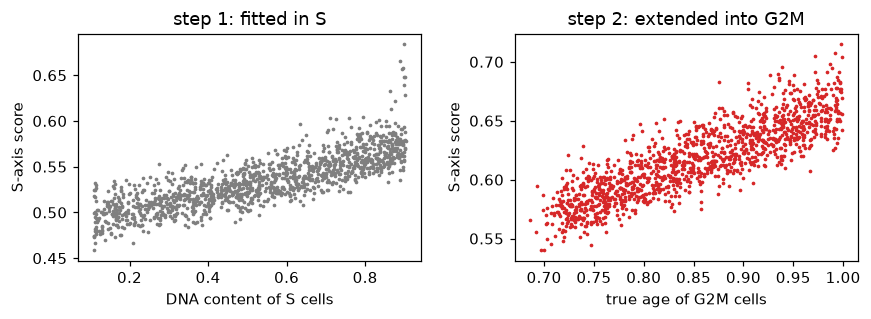

S axis vs DNA content in S: 0.85
S axis vs true age in G2M: 0.87


In [10]:
scaled, projected = _g2m_space(sim[:, g2m_model["features"]].X, g2m_model)
axis_score = projected @ np.asarray(g2m_model["coef"]) + g2m_model["intercept"]
phase = sim.obs["cell_cycle_phase"].astype(str).to_numpy()
in_s, in_g2m = phase == "S", phase == "G2M"
age = sim.obs["age"].to_numpy()
figure, (left, right) = plt.subplots(1, 2, figsize=(8, 3))
left.scatter(sim.obs["Metadata_DNAContent"][in_s], axis_score[in_s], s=2, color="tab:grey", rasterized=True)
left.set(xlabel="DNA content of S cells", ylabel="S-axis score", title="step 1: fitted in S")
right.scatter(age[in_g2m], axis_score[in_g2m], s=2, color="tab:red", rasterized=True)
right.set(xlabel="true age of G2M cells", ylabel="S-axis score", title="step 2: extended into G2M")
plt.tight_layout()
plt.show()
spearman = lambda a, b: pd.Series(np.asarray(a)).corr(pd.Series(np.asarray(b)), method="spearman")
print("S axis vs DNA content in S:", round(spearman(axis_score[in_s], sim.obs["Metadata_DNAContent"][in_s]), 2))
print("S axis vs true age in G2M:", round(spearman(axis_score[in_g2m], age[in_g2m]), 2))

Tubulin gets almost all the weight, at 0.97, area a little, at 0.23, and the noise features almost none. In S,
the axis tracks DNA content with a rank correlation of 0.85.

### Step 2: extending the S axis into G2M

Extended into G2M, where it was never fitted, it still
rises with the true age, with a rank correlation of 0.87, because tubulin keeps rising after S. The extension assumes
that the features which change through S keep changing in the same direction through G2 and mitosis.

### Step 3: a nearest-neighbor graph of the G2M cells

The G2M cells are placed in the weighted space, where each scaled feature is multiplied by its weight before the
principal axes are applied, so features that track DNA in S count most. Each cell is linked to its nearest
neighbors there. The sketch shows 40 cells with 5 neighbors each; the package uses every G2M cell and 30
neighbors.

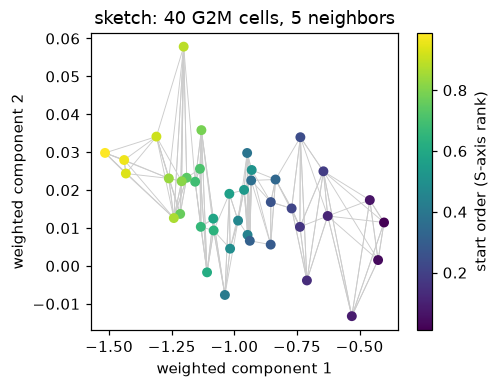

In [11]:
from sklearn.neighbors import NearestNeighbors

weighted = ((scaled - g2m_model["mean"]) * g2m_model["weights"]) @ np.asarray(g2m_model["components"]).T
sketch = np.random.default_rng(5).choice(np.flatnonzero(in_g2m), 40, replace=False)
points = weighted[sketch][:, :2]
links = NearestNeighbors(n_neighbors=6).fit(points).kneighbors(points, return_distance=False)
start = _rank01(axis_score[sketch])
figure, axis = plt.subplots(figsize=(4.5, 3.5))
for cell, neighbors in enumerate(links):
    for other in neighbors[1:]:
        axis.plot(*points[[cell, other]].T, color="0.8", lw=0.6, zorder=0)
dots = axis.scatter(*points.T, c=start, cmap="viridis", s=30, zorder=1)
figure.colorbar(dots, label="start order (S-axis rank)")
axis.set(xlabel="weighted component 1", ylabel="weighted component 2", title="sketch: 40 G2M cells, 5 neighbors")
plt.show()

### Step 4: smoothing the order along the graph

Each cell starts at its rank on the S axis. Smoothing moves each cell's value towards those of its neighbors. The
package solves (I + 10 L) x = start, where L is the graph Laplacian, and ranks the result from 0 to 1. A cell whose
own score is noisy but whose neighbors agree moves towards them.

start: S-axis rank: Spearman with true age 0.87
after smoothing: Spearman with true age 0.94


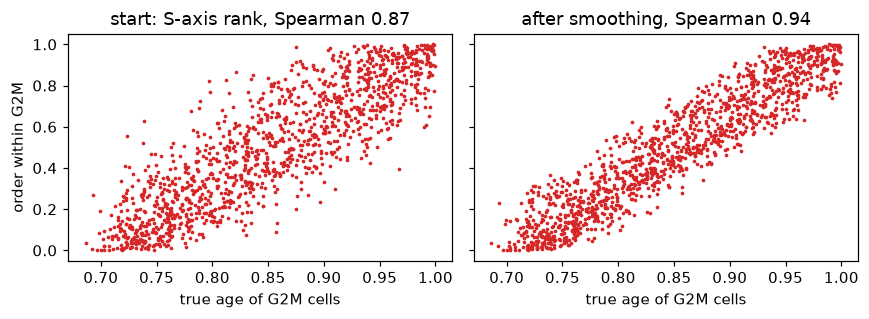

In [12]:
start_all = _rank01(axis_score[in_g2m])
smoothed = sim.obs.loc[in_g2m, "cell_cycle_g2m_order"].to_numpy()
figure, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
for axis, values, title in zip(axes, (start_all, smoothed), ("start: S-axis rank", "after smoothing"), strict=True):
    axis.scatter(age[in_g2m], values, s=2, color="tab:red", rasterized=True)
    axis.set(xlabel="true age of G2M cells", title=f"{title}, Spearman {spearman(values, age[in_g2m]):.2f}")
    print(f"{title}: Spearman with true age {spearman(values, age[in_g2m]):.2f}")
axes[0].set_ylabel("order within G2M")
plt.tight_layout()
plt.show()

Smoothing lifts the rank correlation with the true age from 0.87 to 0.94, because neighbors in the weighted
space average out each cell's measurement noise.

### On real cells

In the optical pooled screen, the screen's own classifier labels each cell interphase or mitotic. Mitotic cells come
at the end of G2M, so a correct order puts them late. The labels are used here only to score the order.

project_cell_cycle: the G2M order is experimental and cannot be validated without a marker of G2 and mitosis; check it against one before reading it biologically


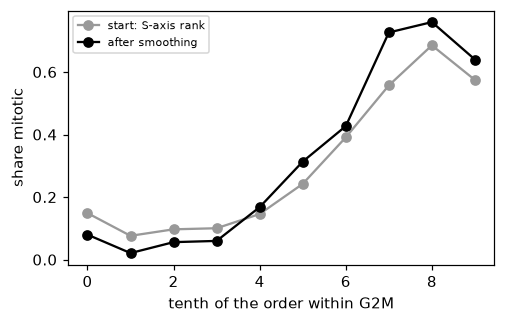

AUROC for mitotic calls, start: 0.77
AUROC for mitotic calls, after smoothing: 0.85


In [13]:
from sklearn.metrics import roc_auc_score

screen = mt.ds.aconcagua(cells=True)
mt.tl.dna_content(
    screen,
    dna_feature="Nuclei_Intensity_IntegratedIntensity_DAPI",
    by=("Metadata_Plate", "Metadata_Well"),
    reference="negcon",
)
mt.tl.fit_cell_cycle(screen, reference="negcon", refine_g2m=True)
mt.tl.project_cell_cycle(screen)
real_model = screen.uns["mantispy"]["cell_cycle"]["g2m"]
check = ((screen.obs["cell_cycle_phase"] == "G2M") & (screen.obs["Metadata_Control_Type"] == "negcon")).to_numpy()
_, real_projected = _g2m_space(screen[check, real_model["features"]].X, real_model)
real_start = _rank01(real_projected @ np.asarray(real_model["coef"]) + real_model["intercept"])
real_order = screen.obs.loc[check, "cell_cycle_g2m_order"].to_numpy()
is_mitotic = (screen.obs.loc[check, "Metadata_Class"] == "Mitotic").to_numpy()

figure, axis = plt.subplots(figsize=(5, 3))
deciles = np.arange(10)
for values, label, color in ((real_start, "start: S-axis rank", "0.6"), (real_order, "after smoothing", "black")):
    share = pd.Series(is_mitotic).groupby(np.minimum((values * 10).astype(int), 9)).mean()
    axis.plot(deciles, share.reindex(deciles), marker="o", color=color, label=label)
axis.set(xlabel="tenth of the order within G2M", ylabel="share mitotic")
axis.legend(fontsize=7)
plt.show()
print("AUROC for mitotic calls, start:", round(roc_auc_score(is_mitotic, real_start), 2))
print("AUROC for mitotic calls, after smoothing:", round(roc_auc_score(is_mitotic, real_order), 2))

In both orders, the share of mitotic cells stays low over the first four tenths and climbs over the rest,
peaking in the ninth tenth and dipping slightly in the last. Smoothing lowers the share in the early tenths and makes
the climb steeper, which raises the AUROC from 0.77 to 0.85.

### Why only G2M

The same smoothing could be run in S or in G1. It is not, and the simulation shows why. In S, DNA content already
places each cell, and an order built from the other features can only blur it. In G1, the simulated tubulin is flat,
so the only feature that changes with age is area, and its change is small next to how much cells differ in size.
The order the graph finds in G1 then follows size, not age. Nothing within G1 tells the two apart without a marker.
The next cell runs the private helper on S and G1 cells to show what would happen.

In [14]:
in_g1 = phase == "G1"
s_order = _g2m_order(sim[in_s, g2m_model["features"]].X, g2m_model)  # private helper, run outside G2M on purpose
g1_order = _g2m_order(sim[in_g1, g2m_model["features"]].X, g2m_model)
size = sim.obs["size"].to_numpy()
pd.DataFrame(
    {
        "Spearman with true age": [
            spearman(sim.obs["cell_cycle_position"][in_s], age[in_s]),
            spearman(s_order, age[in_s]),
            spearman(g1_order, age[in_g1]),
        ],
        "Spearman with cell size": [np.nan, np.nan, spearman(g1_order, size[in_g1])],
    },
    index=["S, position from DNA", "S, order from the graph", "G1, order from the graph"],
).round(2)

,Spearman with true age,Spearman with cell size
"S, position from DNA",0.99,NaN
"S, order from the graph",0.94,NaN
"G1, order from the graph",0.39,0.87


In S, DNA content places cells with a rank correlation of 0.99 with the true age, and the order from the graph
reaches 0.94, so replacing the DNA position would lose precision. In G1, the order from the graph follows cell size,
at 0.87, much more than age, at 0.39. The age signal it picks up comes from area, which grows with age but also carries
the size differences, so within G1 the two cannot be separated without a marker.

### Why it is experimental

On the screen above, the order follows mitosis. During development, it was tested on other datasets with a marker of
G2 and mitosis to check against (results not shown here), and it followed that marker on some and not on others. None of the label-free measures we
tried, such as how well the features predict DNA content in S or how stable the order is, told which datasets it would
work on. The option is therefore off by default, warns every time it runs, and needs an orthogonal marker before its
order is read biologically.

## What the model cannot do

- Order cells within G1 or within G2M from DNA content. There it reports the population prior, and the G2M order
  above is an experimental addition.
- Tell resting G0 cells from G1 cells, or cells in mitosis from cells in G2, since each pair holds the same DNA.
- Describe a reference that is not growing in steady state, such as a population recovering from a block, since the
  conversion from shares to time assumes it.
- Correct a well whose stain reads differently; the well check only reports it.
- Separate every merged pair or fragment from a real cell; the shape checks catch the clear cases.